# DERCONNECT real-data exploration and integration preparation
Checkpoint: November 6, 2026. This notebook is an offline inspection workflow, not dashboard ingestion or fault diagnosis. Clear all outputs before committing. Samples are file prefixes, not random or complete observations.

## A — Dataset overview and provenance
Instructor Haojian Jin supplied January–May 2026 data for five meters (coverage is reported, **not yet verified**). Authorized classifications: E2451 Instructional; E3020 Mixed; E3510/E7080/E7085 Office. Do not infer named buildings or electrical relationships. The approximately 3 GB local archive is not bundled or uploaded. Raw measurements and local reports must stay outside version control.

The dashboard fixtures are simulated hourly kW with simulated weather, occupancy, forecasts, labels and detections; these do not describe this archive. The browser CSV view accepts a separate provisional `timestamp,meter_id,kw` format, not arbitrary raw registers.

Install `requirements-derconnect.txt`, set `DERCONNECT_DATA_PATH` locally, then run all cells. The utility inventories ZIP metadata and streams a bounded prefix of each CSV/TSV. Parquet is optional and only read when the complete member fits the byte budget; larger Parquet needs local metadata/row-group work. Unsupported formats appear as explicit errors. No archive extraction occurs.

In [1]:
import os

os.environ["DERCONNECT_DATA_PATH"] = os.path.expanduser(
    "~/Desktop/Haojian_Data.zip"
)

from pathlib import Path
import os, sys, zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tools/inspect_derconnect.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT / 'tools'))
from inspect_derconnect import inspect, read_member, METERS, UNITS
path_text = os.environ.get('DERCONNECT_DATA_PATH', '')
DATA_PATH = Path(path_text).expanduser() if path_text else None
report = None
if DATA_PATH is None or not DATA_PATH.is_file():
    print('Real data unavailable. Set DERCONNECT_DATA_PATH to your local ZIP and restart/run all. No findings or plots generated.')
else:
    report = inspect(DATA_PATH, rows=2000, max_bytes=8*1024*1024)
    display(pd.Series({k:v for k,v in report.items() if k not in ['files', 'schema_variants']}))
    display(pd.DataFrame([{k:v for k,v in f.items() if k in ['name','meter','months_in_name','format','compressed_bytes','uncompressed_bytes','inspection_error']} for f in report['files']]))

archive_bytes                                                      3513736717
scope                       Per-file prefix samples; no full-data claims o...
file_count                                                                 25
compressed_bytes                                                   3513729939
uncompressed_bytes                                                11945502711
meters_observed_in_paths                  [E2451, E3020, E3510, E7080, E7085]
missing_expected_meters                                                    []
month_note                  Name tokens only; verify timestamp coverage be...
dtype: object

,name,meter,months_in_name,compressed_bytes,uncompressed_bytes,format
0,Haojian_Data/E2451/E2451_2026-01.csv,E2451,[2026-01],143619676,480616583,.csv
1,Haojian_Data/E2451/E2451_2026-02.csv,E2451,[2026-02],129225294,432020055,.csv
2,Haojian_Data/E2451/E2451_2026-03.csv,E2451,[2026-03],143337889,481096826,.csv
3,Haojian_Data/E2451/E2451_2026-04.csv,E2451,[2026-04],139456279,466089014,.csv
4,Haojian_Data/E2451/E2451_2026-05.csv,E2451,[2026-05],144269897,482143079,.csv
5,Haojian_Data/E3020/E3020_2026-04.csv,E3020,[2026-04],135525493,478406882,.csv
6,Haojian_Data/E3020/E3020_2026-03.csv,E3020,[2026-03],139615836,492953066,.csv
7,Haojian_Data/E3020/E3020_2026-05.csv,E3020,[2026-05],140057378,494228518,.csv
8,Haojian_Data/E3020/E3020_2026-02.csv,E3020,[2026-02],126936207,446297374,.csv
9,Haojian_Data/E3020/E3020_2026-01.csv,E3020,[2026-01],140532601,494013272,.csv


## B — Schema inspection
Compare every file's bounded prefix, including failures. String ingestion preserves missing encodings; inferred numeric counts are separate from storage dtype. Expected units below come from the instructor mapping and are **not verified file metadata**. Long-form `register,value,unit` files require an adapter; column-name matching alone cannot establish their availability.

In [2]:
if report:
    display(pd.DataFrame([{'file':f['name'], 'columns':f.get('columns'), 'storage_dtypes':f.get('dtypes'), 'timestamp_candidates':f.get('timestamp_candidates'), 'error':f.get('inspection_error')} for f in report['files']]))
    print('Schema variants:', report['schema_variants'])

,file,columns,storage_dtypes,timestamp_candidates,error
0,Haojian_Data/E2451/E2451_2026-01.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
1,Haojian_Data/E2451/E2451_2026-02.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
2,Haojian_Data/E2451/E2451_2026-03.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
3,Haojian_Data/E2451/E2451_2026-04.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
4,Haojian_Data/E2451/E2451_2026-05.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
5,Haojian_Data/E3020/E3020_2026-04.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
6,Haojian_Data/E3020/E3020_2026-03.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
7,Haojian_Data/E3020/E3020_2026-05.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
8,Haojian_Data/E3020/E3020_2026-02.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
9,Haojian_Data/E3020/E3020_2026-01.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None


Schema variants: [['_time', 'DeviceID', 'Active_Energy_in_Quadrant_I', 'Active_Energy_in_Quadrant_II', 'Active_Energy_in_Quadrant_III', 'Active_Energy_in_Quadrant_IV', 'Active_Power_A', 'Active_Power_B', 'Active_Power_C', 'Apparent_Power_A', 'Apparent_Power_B', 'Apparent_Power_C', 'Current_A', 'Current_B', 'Current_C', 'Current_Unbalance_Worst', 'Frequency', 'Power_Factor_A', 'Power_Factor_B', 'Power_Factor_C', 'Reactive_Power_A', 'Reactive_Power_B', 'Reactive_Power_C', 'THD_Current_A', 'THD_Current_B', 'THD_Current_C', 'THD_Current_N', 'THD_Voltage_A-N', 'THD_Voltage_B-N', 'THD_Voltage_C-N', 'Voltage_A-B', 'Voltage_A-N', 'Voltage_B-C', 'Voltage_B-N', 'Voltage_C-A', 'Voltage_C-N', 'Voltage_Unbalance_L-N_Worst']]


## C — Timestamp and sampling analysis
ISO timestamps only: choose `--timestamp` for ambiguous candidates; epoch, split date/time and local formats require explicit parsing rules. Cadence is the modal positive interval in file order, separately per file/meter. Duplicates and backwards steps are retained as evidence. Gaps use sorted unique times and a 1.5× modal interval threshold; off-cadence uses 1% tolerance. These are diagnostics, not a verified schedule. Cross-file duplicates and full-month coverage remain untested.

Naive timestamps stay naive: do not localize without source confirmation. Campus `America/Los_Angeles` crosses DST on March 8, 2026; nonexistent local times require a documented rule. Explicit offsets identify instants but do not prove a timezone. No real-data use of the dashboard's wall-time-as-UTC shortcut.

In [3]:
if report:
    display(pd.DataFrame([{'file':f['name'], 'meter':f['meter'], **f.get('time', {}), 'note':f.get('time_warning')} for f in report['files']]))
    expected = {f'2026-{m:02}' for m in range(1,6)}
    for meter in METERS:
        observed = {token.replace('_','-') if len(token)==7 else token[:4]+'-'+token[4:] for f in report['files'] if f['meter']==meter for token in f['months_in_name']}
        print(meter, 'missing filename tokens:', sorted(expected-observed), 'unexpected:', sorted(observed-expected))
    print('Filename-month checks are provisional; use timestamps to verify actual coverage.')

,file,meter,parsed,invalid,naive,offset_aware,start,end,duplicate_timestamps,backwards,interval_counts_seconds,modal_interval_seconds,large_gaps,off_cadence,max_gap_seconds,warning,note
0,Haojian_Data/E2451/E2451_2026-01.csv,E2451,2000,0,0,2000,2026-01-01T08:00:00.173662+00:00,2026-01-01T09:06:38.294606+00:00,0,0,"[(2.000324, 5), (1.999874, 5), (1.999929, 5), ...",2.000324,0,0,2.004022,Offsets do not identify a campus timezone,None
1,Haojian_Data/E2451/E2451_2026-02.csv,E2451,2000,0,0,2000,2026-02-01T08:00:01.983799+00:00,2026-02-01T09:06:40.106640+00:00,0,0,"[(2.000529, 7), (2.000067, 6), (1.999802, 5), ...",2.000529,0,2,2.024472,Offsets do not identify a campus timezone,None
2,Haojian_Data/E2451/E2451_2026-03.csv,E2451,2000,0,0,2000,2026-03-01T08:00:01.025074+00:00,2026-03-01T09:06:39.164847+00:00,0,0,"[(1.999973, 5), (2.000434, 4), (2.000538, 4), ...",1.999973,0,322,2.045036,Offsets do not identify a campus timezone,None
3,Haojian_Data/E2451/E2451_2026-04.csv,E2451,2000,0,0,2000,2026-04-01T07:00:01.688498+00:00,2026-04-01T08:06:39.814754+00:00,0,0,"[(1.999855, 6), (2.000135, 6), (1.999827, 5), ...",1.999855,0,109,2.029708,Offsets do not identify a campus timezone,None
4,Haojian_Data/E2451/E2451_2026-05.csv,E2451,2000,0,0,2000,2026-05-01T07:00:00.322278+00:00,2026-05-01T08:06:38.481990+00:00,0,0,"[(2.00028, 6), (1.999836, 5), (2.000113, 5), (...",2.000280,0,16,2.023779,Offsets do not identify a campus timezone,None
5,Haojian_Data/E3020/E3020_2026-04.csv,E3020,2000,0,0,2000,2026-04-01T07:00:01.769625+00:00,2026-04-01T08:06:39.897169+00:00,0,0,"[(2.002963, 2), (1.978699, 2), (2.002466, 2), ...",2.002963,0,590,2.228446,Offsets do not identify a campus timezone,None
6,Haojian_Data/E3020/E3020_2026-03.csv,E3020,2000,0,0,2000,2026-03-01T08:00:01.106570+00:00,2026-03-01T09:06:39.265906+00:00,0,0,"[(2.000077, 3), (2.001187, 2), (2.000814, 2), ...",2.000077,0,694,2.177354,Offsets do not identify a campus timezone,None
7,Haojian_Data/E3020/E3020_2026-05.csv,E3020,2000,0,0,2000,2026-05-01T07:00:00.403158+00:00,2026-05-01T08:06:38.564396+00:00,0,0,"[(2.000229, 3), (2.002951, 3), (2.000533, 3), ...",2.000229,0,218,2.103268,Offsets do not identify a campus timezone,None
8,Haojian_Data/E3020/E3020_2026-02.csv,E3020,2000,0,0,2000,2026-02-01T08:00:00.064319+00:00,2026-02-01T09:06:38.214468+00:00,0,0,"[(2.00288, 3), (2.003294, 3), (1.999792, 3), (...",2.002880,0,430,2.072794,Offsets do not identify a campus timezone,None
9,Haojian_Data/E3020/E3020_2026-01.csv,E3020,2000,0,0,2000,2026-01-01T08:00:00.257808+00:00,2026-01-01T09:06:38.398942+00:00,0,0,"[(2.000298, 4), (1.998832, 3), (2.000385, 3), ...",2.000298,0,490,2.039254,Offsets do not identify a campus timezone,None


E2451 missing filename tokens: [] unexpected: []
E3020 missing filename tokens: [] unexpected: []
E3510 missing filename tokens: [] unexpected: []
E7080 missing filename tokens: [] unexpected: []
E7085 missing filename tokens: [] unexpected: []
Filename-month checks are provisional; use timestamps to verify actual coverage.


## D — Measurement availability and quality
The matrix means “column observed in a sampled schema”, not “valid data for the full period”. Unknown names and metadata remain in the schema table. Ranges, missing encodings and nonnumeric counts are bounded diagnostics; units require source confirmation. Do not treat counter energy as power.

In [4]:
if report:
    availability = pd.DataFrame({m:{r:any(r in f.get('columns',[]) for f in report['files'] if f['meter']==m) for r in UNITS} for m in METERS})
    display(availability)
    quality = pd.DataFrame([{'meter':f['meter'], 'file':f['name'], 'column':c, 'expected_unit':UNITS.get(c), **q} for f in report['files'] for c,q in f.get('quality',{}).items()])
    display(quality)

,E2451,E3020,E3510,E7080,E7085
Active_Energy_in_Quadrant_I,True,True,True,True,True
Active_Energy_in_Quadrant_II,True,True,True,True,True
Active_Energy_in_Quadrant_III,True,True,True,True,True
Active_Energy_in_Quadrant_IV,True,True,True,True,True
Active_Power_A,True,True,True,True,True
Active_Power_B,True,True,True,True,True
Active_Power_C,True,True,True,True,True
Apparent_Power_A,True,True,True,True,True
Apparent_Power_B,True,True,True,True,True
Apparent_Power_C,True,True,True,True,True


,meter,file,column,expected_unit,missing,non_numeric,nonfinite,numeric_count,min,max,negative,adjacent_equal,decreases
0,E2451,Haojian_Data/E2451/E2451_2026-01.csv,_time,NaN,0,2000,0,0,NaN,NaN,0,0,0
1,E2451,Haojian_Data/E2451/E2451_2026-01.csv,DeviceID,NaN,0,2000,0,0,NaN,NaN,0,0,0
2,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_I,kWh,0,0,0,2000,3.073328e+06,3.073369e+06,0,1833,0
3,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_II,kWh,0,0,0,2000,3.000000e-05,3.000000e-05,0,1999,0
4,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_III,kWh,0,0,0,2000,0.000000e+00,0.000000e+00,0,1999,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
920,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_B-C,V,0,0,0,2000,4.850290e+02,4.888888e+02,0,156,931
921,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_B-N,V,0,0,0,2000,2.797855e+02,2.820201e+02,0,157,929
922,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_C-A,V,0,0,0,2000,4.843855e+02,4.883060e+02,0,157,926
923,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_C-N,V,0,0,0,2000,2.799835e+02,2.822246e+02,0,156,932


## E — Exploratory visualizations
Choose a successfully inspected file and an exact register. No automatic phase sum is calculated: phase compatibility, simultaneity, net/import conventions and register semantics need confirmation. Hour/day profiles below are retrospective sample means, not energy or complete daily totals. UTC hours for offset-aware timestamps are not campus occupancy hours. Short file prefixes rarely support weekly conclusions.

Run the selected-file cell for each meter and supported voltage/frequency/current/phase register. Compare building classes only with matched windows, cadences and confirmed units; no class comparison is valid from unmatched prefixes. Change `SELECTED_NAME` to select a file explicitly.

Bounded prefix: Haojian_Data/E2451/E2451_2026-01.csv limited: True


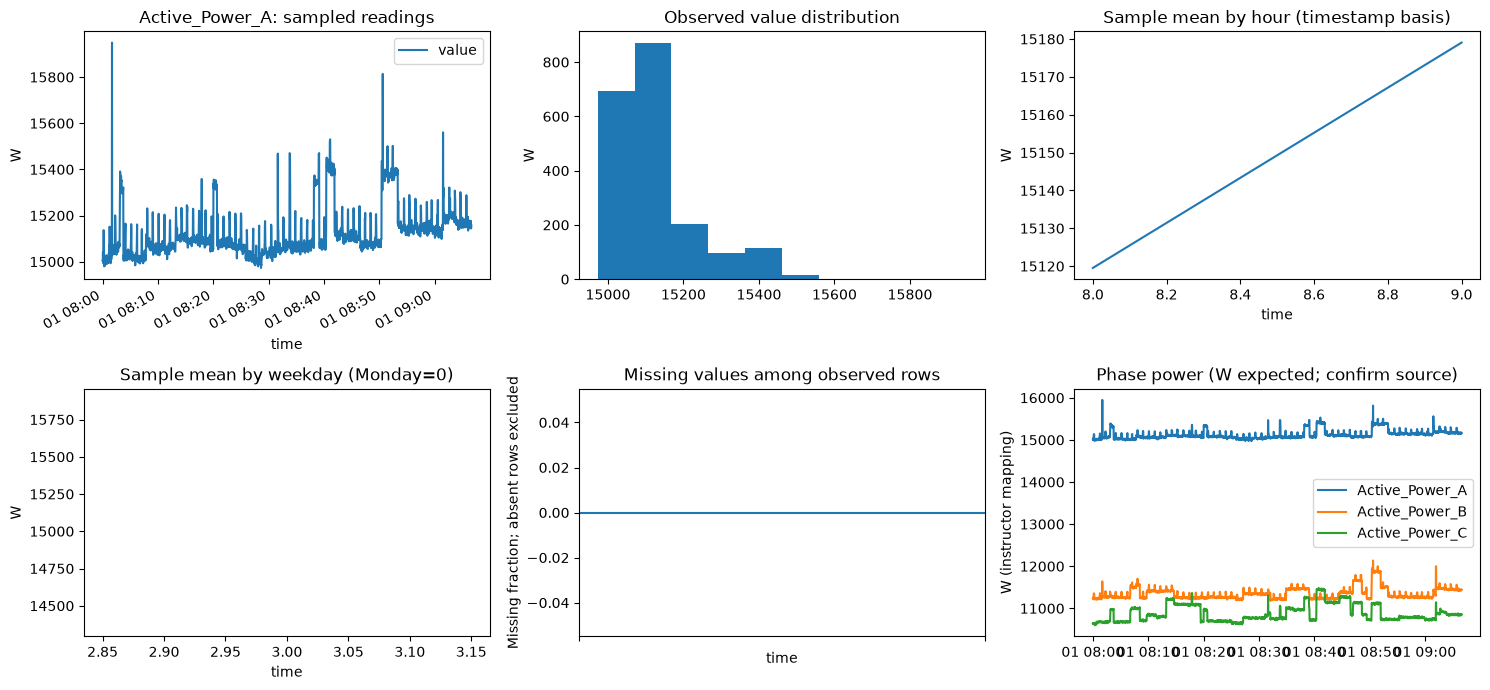

In [5]:
SELECTED_NAME = None
REGISTER = 'Active_Power_A'
frame = None
if report:
    candidates = [f for f in report['files'] if 'time_column' in f and REGISTER in f.get('columns', [])]
    selected = next((f for f in candidates if f['name']==SELECTED_NAME), None) if SELECTED_NAME else next(iter(candidates), None)
    if selected:
        with zipfile.ZipFile(DATA_PATH) as archive:
            frame, limited = read_member(archive, archive.getinfo(selected['name']), rows=2000)
        print('Bounded prefix:', selected['name'], 'limited:', limited)
    else:
        print('No supported timestamp/register pair. Inspect schema and select a register/parser; no plot generated.')
if frame is not None:
    if selected.get('time', {}).get('naive') and selected.get('time', {}).get('offset_aware'):
        print('Mixed time bases: resolve before plotting.')
    else:
        t = pd.to_datetime(frame[selected['time_column']], errors='coerce', utc=bool(selected.get('time',{}).get('offset_aware')))
        v = pd.to_numeric(frame[REGISTER], errors='coerce').replace([float('inf'), -float('inf')], float('nan'))
        sample = pd.DataFrame({'time':t, 'value':v}).dropna(subset=['time']).sort_values('time')
        unit = UNITS.get(REGISTER, 'unverified unit')
        fig, axes = plt.subplots(2, 3, figsize=(15,7))
        sample.plot(x='time', y='value', ax=axes[0,0], title=f'{REGISTER}: sampled readings')
        sample['value'].plot.hist(ax=axes[0,1], title='Observed value distribution')
        sample.groupby(sample.time.dt.hour)['value'].mean().plot(ax=axes[0,2], title='Sample mean by hour (timestamp basis)')
        sample.groupby(sample.time.dt.dayofweek)['value'].mean().plot(ax=axes[1,0], title='Sample mean by weekday (Monday=0)')
        sample.set_index('time')['value'].isna().resample('h').mean().plot(ax=axes[1,1], title='Missing values among observed rows')
        phases = [c for c in ['Active_Power_A','Active_Power_B','Active_Power_C'] if c in frame]
        for c in phases:
            axes[1,2].plot(t, pd.to_numeric(frame[c], errors='coerce'), label=c)
        axes[1,2].set_title('Phase power (W expected; confirm source)')
        if phases: axes[1,2].legend()
        for ax in axes.flat: ax.set_ylabel(unit)
        axes[1,1].set_ylabel('Missing fraction; absent rows excluded')
        axes[1,2].set_ylabel('W (instructor mapping)')
        plt.tight_layout()
        plt.show()

## Preliminary DERCONNECT Dataset Findings

**Dataset source:** Initial DERCONNECT meter dataset shared by Haojian Jin, covering January–May 2026.

### Dataset structure

- The archive contains 25 monthly CSV files organized across five meter/device IDs: E2451, E3020, E3510, E7080, and E7085.
- The archive is approximately 3.5 GB compressed and 11.9 GB uncompressed.
- All five devices have a file for each month from January through May 2026.
- The inspected files share a consistent schema covering active energy, active and apparent power, voltage, current, frequency, power factor, reactive power, harmonic distortion, and phase unbalance.

### Preliminary data quality and sampling

- The sampled timestamps use the `_time` column and include UTC offsets.
- Observations appear to occur approximately every two seconds.
- The initial inspection examined 2,000 rows per monthly file.
- No invalid or duplicate timestamps were identified within those inspected samples.
- The selected measurement registers showed generally complete values in the sampled rows.
- Some registers were constant within the sampled intervals, requiring further investigation.

### Initial visualization

- Real active-power measurements were successfully visualized.
- Short-term load fluctuations and differences between electrical phases were visible.
- The current sampling window spans approximately 67 minutes per file, limiting conclusions about daily and weekly patterns.
- Longer-period aggregation is needed before comparing typical behavior across building types or identifying unusual consumption patterns.

### Implications for dashboard integration

- Raw two-second measurements are unnecessarily detailed for many campus-level dashboard visualizations.
- A reproducible aggregation layer will likely be needed for interactive building-level trends.
- Original-resolution measurements may remain useful for inspecting short-duration events.
- Building identities should remain tied to their provided device IDs until physical building names are verified.
- Real measurements should remain distinguishable from the existing synthetic demonstration dataset.

### Next steps

1. Perform memory-efficient full-period quality and coverage analysis.
2. Evaluate five-minute, fifteen-minute, and hourly aggregation.
3. Verify active-power phase aggregation and timestamp conventions.
4. Coordinate with the anomaly detection team on model input requirements.
5. Define a common data interface for real measurements, forecasts, anomaly scores, and detected events.

**Limitations:** These are preliminary findings based on bounded file-prefix samples, not a comprehensive analysis of the full five-month dataset. No operational electrical faults have been confirmed.